# 와인 품질 판별

데이터 감사 → 학습 전용 EDA → 분할 → Pipeline 학습 → 검증 선택 → 테스트 평가 → 예측. 저장소 루트에서 실행합니다. 이 노트북의 학습 셀은 보고서와 모델을 재생성합니다.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from train import load_data, split_data, train
from predict import predict
import joblib
X, y, audit = load_data()
display(pd.Series(audit).to_frame("data audit"))
display(X.head())

,data audit
raw_rows,1599
rows,1359
duplicates_removed,240
conflicting_rows_removed,0
missing_cells,0
positive_rate,0.135394
features,"[fixed acidity, volatile acidity, citric acid,..."
source_url,https://archive.ics.uci.edu/static/public/186/...
raw_sha256,4a402cf041b025d4566d954c3b9ba8635a3a8a01e03900...


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4


## 분할과 특성 분포

60/20/20 층화 분할을 수행합니다. 원본 행 중복과 같은 입력의 상충 타깃은 분할 전에 제거합니다. EDA에는 학습 데이터만 사용합니다.

In [2]:
Xtr, Xv, Xt, ytr, yv, yt = split_data(X, y)
display(pd.DataFrame({"rows": [len(Xtr),len(Xv),len(Xt)], "positive_rate": [ytr.mean(),yv.mean(),yt.mean()]}, index=["train","validation","test"]))
display(Xtr.describe(include="all").T)

,rows,positive_rate
train,815,0.134969
validation,272,0.136029
test,272,0.136029


,count,mean,std,min,25%,50%,75%,max
fixed acidity,815.0,8.351779,1.799978,4.60000,7.1000,7.90000,9.300000,15.90000
volatile acidity,815.0,0.526000,0.185568,0.12000,0.3800,0.51000,0.630000,1.58000
citric acid,815.0,0.278479,0.191378,0.00000,0.1050,0.26000,0.430000,0.79000
residual sugar,815.0,2.531043,1.322077,0.90000,1.9000,2.20000,2.600000,15.40000
chlorides,815.0,0.087189,0.047498,0.01200,0.0705,0.07900,0.090000,0.61100
free sulfur dioxide,815.0,16.180982,10.470624,2.00000,8.0000,14.00000,21.000000,72.00000
total sulfur dioxide,815.0,48.374233,34.673749,6.00000,23.0000,40.00000,64.000000,289.00000
density,815.0,0.996734,0.001830,0.99007,0.9957,0.99672,0.997825,1.00369
pH,815.0,3.307472,0.160239,2.86000,3.2100,3.31000,3.395000,4.01000
sulphates,815.0,0.661460,0.178804,0.37000,0.5500,0.62000,0.730000,1.98000


## 학습과 검증 선택

스케일링 전후 LogisticRegression, 깊이가 제한된 트리, 과적합 관찰용 무제한 트리를 비교합니다. 쇼핑몰은 RandomForest도 비교합니다. 검증 AP로 모델, 검증 F1으로 임계값을 선택하며 테스트는 선택이 끝난 뒤 평가합니다.

In [3]:
result = train()

{
  "selected_model": "tree_depth_5",
  "threshold": 0.30000000000000004,
  "split_sizes": {
    "train": 815,
    "validation": 272,
    "test": 272
  },
  "test": {
    "accuracy": 0.875,
    "precision": 0.5365853658536586,
    "recall": 0.5945945945945946,
    "f1": 0.5641025641025641,
    "roc_auc": 0.7477285796434733,
    "average_precision": 0.4453029317022602
  }
}


,model,convergence_warning,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,train_average_precision,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_average_precision
0,dummy,False,0.865031,0.000000,0.000000,0.000000,0.500000,0.134969,0.863971,0.000000,0.000000,0.000000,0.500000,0.136029,0.863971,0.000000,0.000000,0.000000,0.500000,0.136029
1,logistic_unscaled,False,0.877301,0.619048,0.236364,0.342105,0.866074,0.484943,0.878676,0.642857,0.243243,0.352941,0.901783,0.530158,0.875000,0.615385,0.216216,0.320000,0.879816,0.497289
2,logistic_scaled,False,0.879755,0.607143,0.309091,0.409639,0.875899,0.525770,0.871324,0.550000,0.297297,0.385965,0.879701,0.479447,0.875000,0.578947,0.297297,0.392857,0.885221,0.534435
3,tree_depth_3,False,0.893252,0.767442,0.300000,0.431373,0.845235,0.518318,0.886029,0.750000,0.243243,0.367347,0.849396,0.533165,0.893382,0.785714,0.297297,0.431373,0.839620,0.496702
4,tree_depth_5,False,0.910429,0.707865,0.572727,0.633166,0.927008,0.708617,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871,0.875000,0.555556,0.405405,0.468750,0.747729,0.445303
5,tree_depth_8,False,0.910429,0.707865,0.572727,0.633166,0.946970,0.729420,0.889706,0.652174,0.405405,0.500000,0.847556,0.500948,0.875000,0.555556,0.405405,0.468750,0.774871,0.438090
6,tree_unrestricted_diagnostic,False,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.830882,0.378378,0.378378,0.378378,0.640253,0.227729,0.845588,0.444444,0.540541,0.487805,0.717079,0.302740


,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,0.10,0.779412,0.358025,0.783784,0.491525,0.855952,0.534871
1,0.15,0.849265,0.465517,0.729730,0.568421,0.855952,0.534871
2,0.20,0.875000,0.529412,0.729730,0.613636,0.855952,0.534871
3,0.25,0.897059,0.604651,0.702703,0.650000,0.855952,0.534871
4,0.30,0.897059,0.604651,0.702703,0.650000,0.855952,0.534871
5,0.35,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871
6,0.40,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871
7,0.45,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871
8,0.50,0.893382,0.700000,0.378378,0.491228,0.855952,0.534871
9,0.55,0.875000,0.636364,0.189189,0.291667,0.855952,0.534871


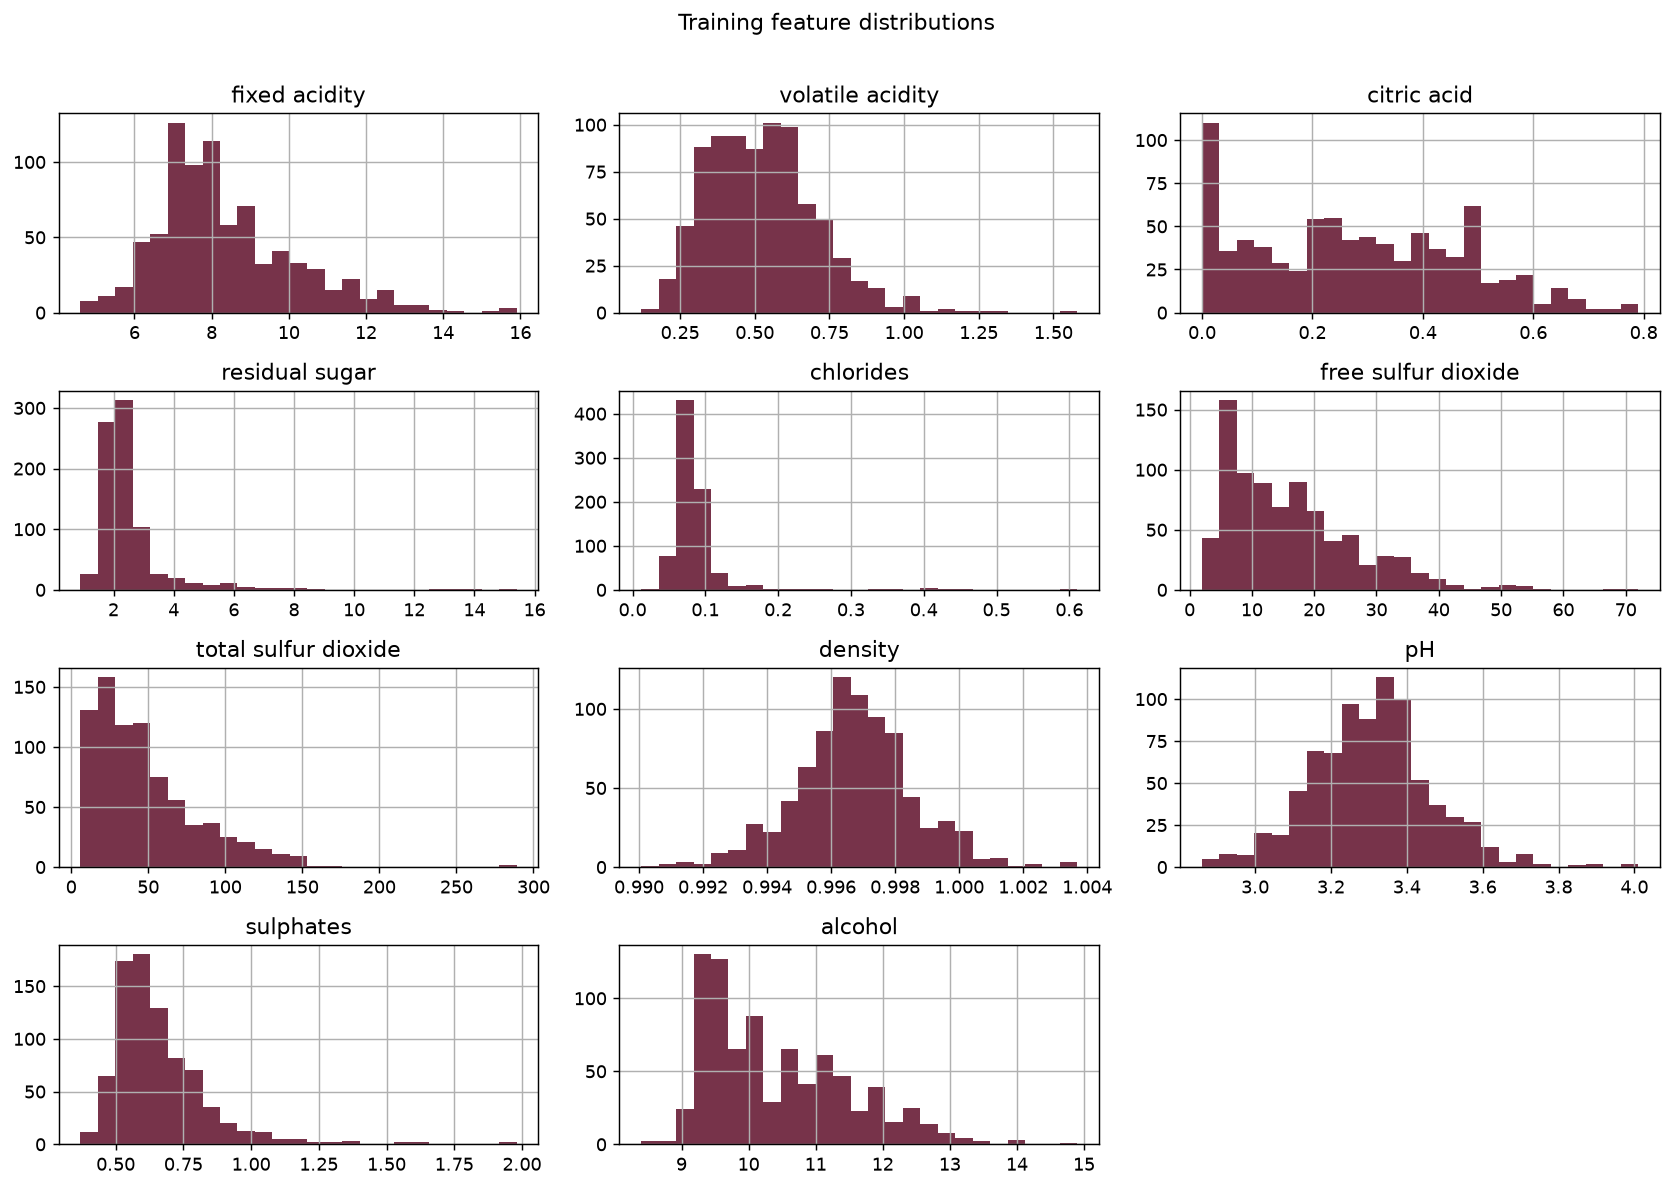

In [4]:
comparison = pd.read_csv("model_comparison.csv")
display(comparison)
display(pd.read_csv("validation_thresholds.csv"))
display(Image(filename="feature_distributions.png"))

## 혼동 행렬·정밀도·재현율과 오답

행은 실제, 열은 예측입니다. 정밀도는 양성 예측의 적중 비율, 재현율은 실제 양성을 찾아낸 비율입니다. 불균형 데이터에서 정확도와 양성 탐지 성능을 함께 해석합니다.

,test
accuracy,0.875000
precision,0.536585
recall,0.594595
f1,0.564103
roc_auc,0.747729
average_precision,0.445303


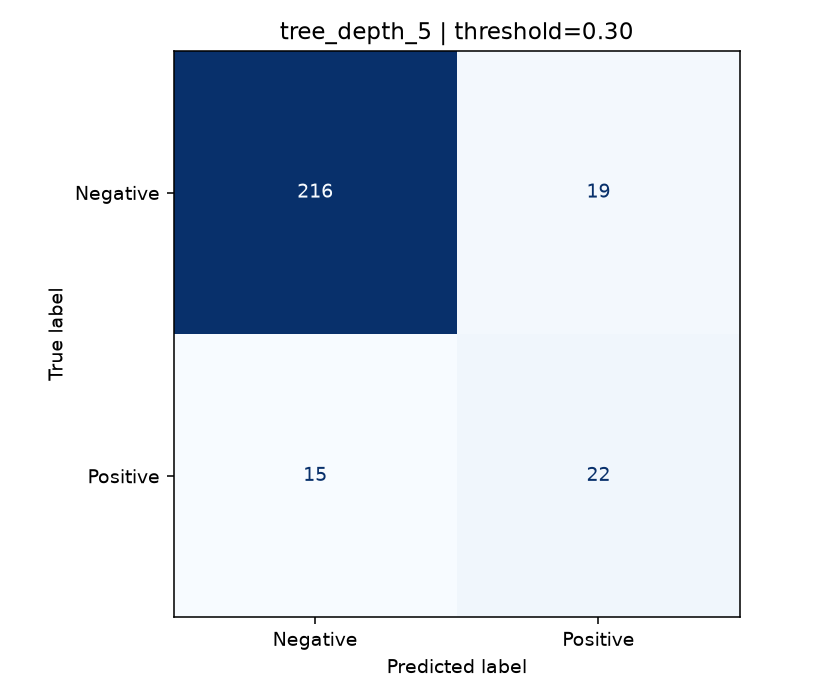

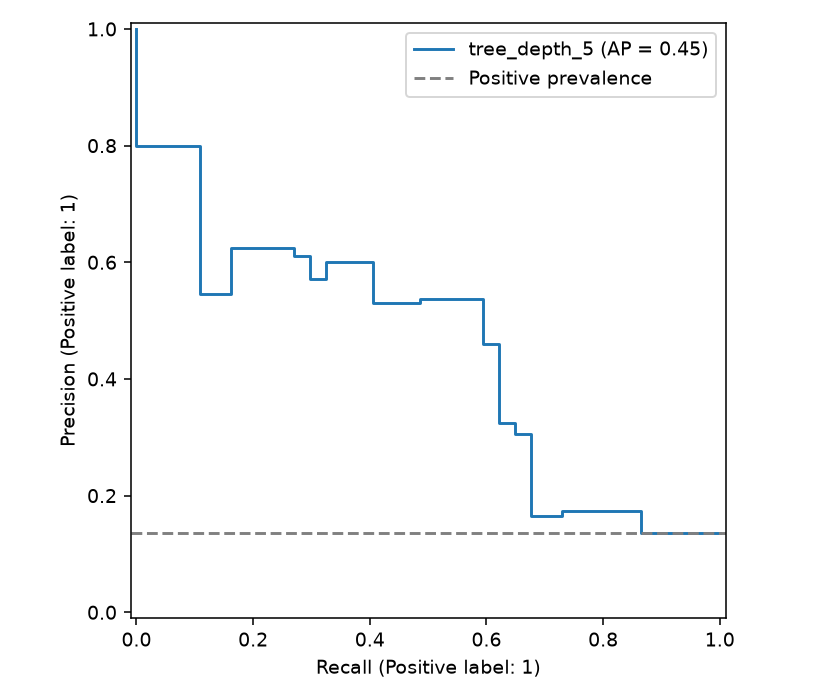

,source_row,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,actual,probability,predicted,error_type,confidence
0,288,8.7,0.52,0.09,2.5,0.091,20.0,49.0,0.99760,3.34,0.86,10.6,1,0.000000,0,FN,1.000000
1,1086,8.5,0.34,0.40,4.7,0.055,3.0,9.0,0.99738,3.38,0.66,11.6,1,0.000000,0,FN,1.000000
2,336,8.9,0.43,0.45,1.9,0.052,6.0,16.0,0.99480,3.35,0.70,12.5,0,1.000000,1,FP,1.000000
3,1003,6.8,0.36,0.32,1.8,0.067,4.0,8.0,0.99280,3.36,0.55,12.8,1,0.000000,0,FN,1.000000
4,1111,5.4,0.42,0.27,2.0,0.092,23.0,55.0,0.99471,3.78,0.64,12.3,1,0.000000,0,FN,1.000000
5,1534,6.6,0.56,0.14,2.4,0.064,13.0,29.0,0.99397,3.42,0.62,11.7,1,0.000000,0,FN,1.000000
6,209,11.0,0.30,0.58,2.1,0.054,7.0,19.0,0.99800,3.31,0.88,10.5,1,0.019231,0,FN,0.980769
7,589,10.2,0.29,0.49,2.6,0.059,5.0,13.0,0.99760,3.05,0.74,10.5,1,0.019231,0,FN,0.980769
8,200,9.6,0.32,0.47,1.4,0.056,9.0,24.0,0.99695,3.22,0.82,10.3,1,0.019231,0,FN,0.980769
9,281,7.7,0.27,0.68,3.5,0.358,5.0,10.0,0.99720,3.25,1.08,9.9,1,0.019231,0,FN,0.980769


In [5]:
display(pd.Series(result["test"]).to_frame("test"))
display(Image(filename="confusion_matrix.png"))
display(Image(filename="precision_recall.png"))
display(pd.read_csv("misclassified.csv").head(10))

## 특성 중요도와 해석

검증 데이터에서 원본 열을 8회 섞었을 때 AP 하락량을 측정합니다. 모델이 의존하는 예측 연관성으로 해석하며, 인과 효과로 해석하지 않습니다.

,feature,mean_ap_decrease,std_ap_decrease
0,alcohol,0.271286,0.022251
1,sulphates,0.187709,0.029228
2,pH,0.065613,0.030856
3,volatile acidity,0.039727,0.015217
4,free sulfur dioxide,0.033227,0.027400
5,residual sugar,0.014843,0.014304
6,fixed acidity,0.004045,0.003536
7,chlorides,0.001108,0.003568
8,total sulfur dioxide,-0.001782,0.006665
9,density,-0.003473,0.003390


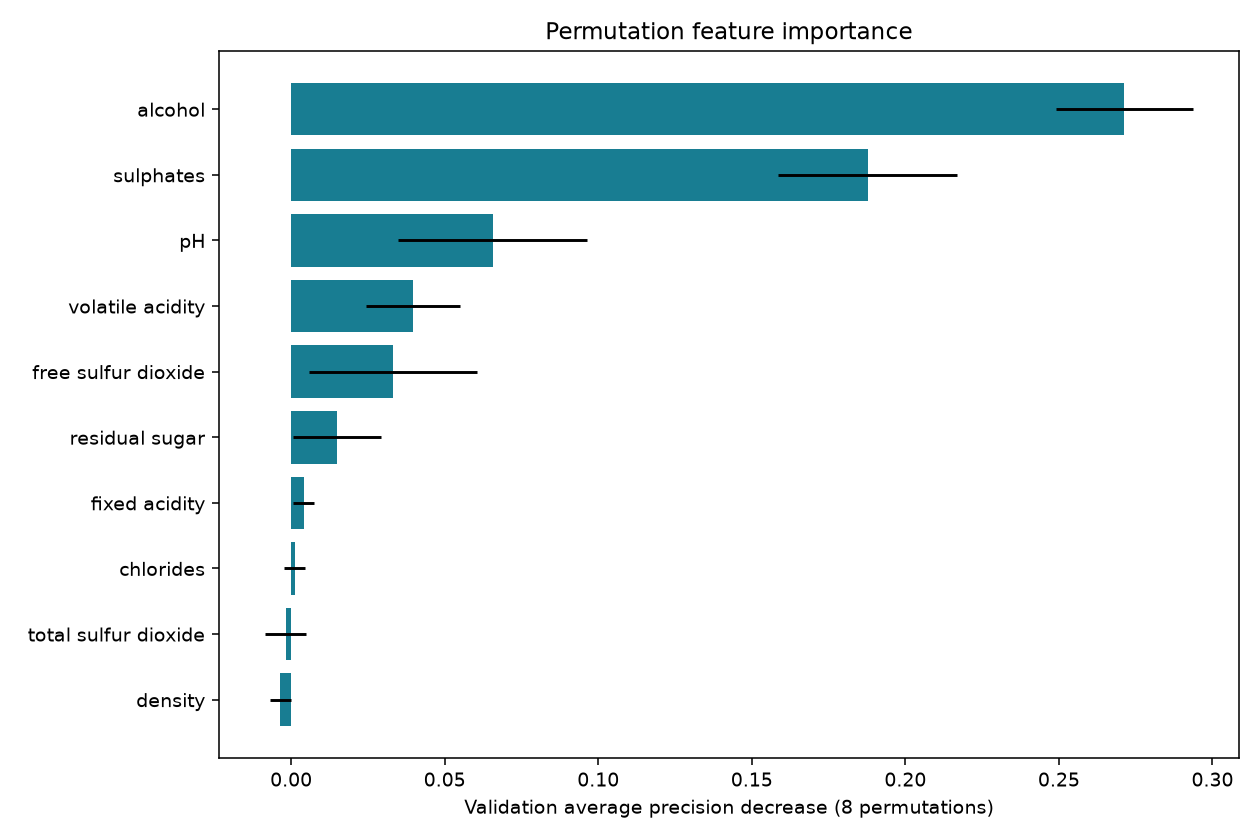

In [6]:
display(pd.read_csv("feature_importance.csv"))
display(Image(filename="feature_importance.png"))

## 성분 또는 행동 입력으로 예측

JSON 예제에서 값을 수정하여 다시 실행합니다. 학습 범위를 벗어나는 숫자는 결과에 표시됩니다.

In [7]:
sample = json.loads(Path("sample_input.json").read_text(encoding="utf-8"))
bundle = joblib.load("model.joblib")
display(sample)
display(predict(sample, bundle))

{'fixed acidity': 6.9,
 'volatile acidity': 0.49,
 'citric acid': 0.19,
 'residual sugar': 1.7,
 'chlorides': 0.079,
 'free sulfur dioxide': 13.0,
 'total sulfur dioxide': 26.0,
 'density': 0.99547,
 'pH': 3.38,
 'sulphates': 0.64,
 'alcohol': 9.8}

{'label': '일반',
 'prediction': 0,
 'positive_probability': 0.034482758620689655,
 'threshold': 0.30000000000000004,
 'outside_training_range': []}

## 종합 평가

데이터 출처와 이용 조건은 DATA_SOURCES.md를 참고하세요. 모델 확률은 보정하지 않았으며 이 결과는 오프라인 교육용 실험입니다.

In [8]:
display(Markdown(Path("evaluation.md").read_text(encoding="utf-8")))

# 와인 품질 성능 평가서

## 문제와 데이터
양성은 **우수 와인(원점수 7 이상)**입니다. 원본 1,599행에서 입력·타깃이 동일한 중복 240행, 동일 입력의 상충 타깃 0행을 제거해 1,359행을 사용했습니다. 결측 셀은 0개, 양성 비율은 13.54%입니다. 원본 인덱스와 분할은 `split_manifest.csv`, 원본 파일 SHA-256은 `metrics.json`에 기록했습니다.

## 평가 설계
`random_state=42`로 양성 비율을 유지하여 학습/검증/테스트를 60/20/20으로 분리했습니다. 실제 건수는 {'train': 815, 'validation': 272, 'test': 272}입니다. 스케일러·결측 대체·인코더는 Pipeline 안에서 학습 세트로만 적합합니다. EDA도 학습 세트만 사용합니다.
모델은 검증 **Average Precision(AP)** 최대값으로 선택하고, 선택 모델의 임계값은 검증 F1이 최대인 값(0.10~0.90, 간격 0.05)으로 정했습니다. 동률이면 큰 임계값을 사용합니다. AP는 불균형 데이터의 순위 품질을 측정하며, 사다리꼴 PR-AUC와 계산이 다릅니다.
최종 선택은 **tree_depth_5**, 임계값은 **0.30**입니다. 테스트 결과는 선택에 사용하지 않았고, 검증 중요도 평가를 위해 최종 모델을 학습+검증으로 재적합하지 않았습니다. 무제한 트리는 과적합 관찰용으로 선택 대상에서 제외했습니다.

## 모델 비교 — 공통 임계값 0.50
| model | train_f1 | validation_f1 | validation_average_precision | test_accuracy | test_f1 |
| --- | --- | --- | --- | --- | --- |
| dummy | 0.0000 | 0.0000 | 0.1360 | 0.8640 | 0.0000 |
| logistic_unscaled | 0.3421 | 0.3529 | 0.5302 | 0.8750 | 0.3200 |
| logistic_scaled | 0.4096 | 0.3860 | 0.4794 | 0.8750 | 0.3929 |
| tree_depth_3 | 0.4314 | 0.3673 | 0.5332 | 0.8934 | 0.4314 |
| tree_depth_5 | 0.6332 | 0.5000 | 0.5349 | 0.8750 | 0.4688 |
| tree_depth_8 | 0.6332 | 0.5000 | 0.5009 | 0.8750 | 0.4688 |
| tree_unrestricted_diagnostic | 1.0000 | 0.3784 | 0.2277 | 0.8456 | 0.4878 |

모든 후보는 같은 분할을 사용합니다. 아래 최종 성능은 조정 임계값을 사용하므로 위 표의 0.50 결과와 다를 수 있습니다. 스케일링 비교는 같은 LogisticRegression 설정에서 수행합니다. 표준화는 각 특성을 학습 평균 0·표준편차 1로 바꾸며, 정규화 제약과 최적화에 영향을 줍니다. 트리는 분기 순서를 사용하므로 스케일링을 생략했습니다.
수렴 경고가 나온 후보: **없음**. 경고가 있는 비표준화 LogisticRegression은 최적화가 완료되지 않은 비교 실험이며, 그 성능을 수렴한 모델의 확정적 한계로 해석하지 않습니다. `model_comparison.csv`의 convergence_warning 열에도 기록했습니다.

## 최종 테스트 성능
| 정확도 | 정밀도 | 재현율 | F1 | ROC-AUC | AP |
| --- | --- | --- | --- | --- | --- |
| 0.8750 | 0.5366 | 0.5946 | 0.5641 | 0.7477 | 0.4453 |

혼동 행렬의 행은 실제, 열은 예측이며 순서는 음성(0), 양성(1)입니다: **TN=216, FP=19, FN=15, TP=22**.
다수 클래스 기준 모델의 테스트 정확도는 **0.8640**입니다. 최종 정확도가 이보다 낮아도 양성 탐지 F1과 재현율이 개선될 수 있습니다. 이 선택은 매출이나 비용 최적화를 의미하지 않습니다.
정밀도 TP/(TP+FP)는 양성 예측의 적중률, 재현율 TP/(TP+FN)는 실제 양성을 찾아낸 비율입니다. FP는 일반 와인을 우수로 잘못 추천하는 오류, FN은 우수 와인을 놓치는 오류입니다.

![혼동 행렬](confusion_matrix.png)
![정밀도 재현율 곡선](precision_recall.png)

## 과적합과 오답 노트
무제한 트리의 학습 F1=1.0000, 검증 F1=0.3784입니다. 깊이 3·5·8 및 최소 잎 표본 10으로 제한한 트리와 비교해 일반화 차이를 확인합니다.
테스트 오답 34건 전체를 `misclassified.csv`에 저장했습니다. FP/FN, 실제값, 예측값, 확률, 원본 행 번호와 입력 성분/행동을 확인할 수 있습니다. 확신이 큰 오답 5건은 다음과 같습니다.

| source_row | actual | predicted | probability | error_type |
| --- | --- | --- | --- | --- |
| 288 | 1 | 0 | 0.0000 | FN |
| 1086 | 1 | 0 | 0.0000 | FN |
| 336 | 0 | 1 | 1.0000 | FP |
| 1003 | 1 | 0 | 0.0000 | FN |
| 1111 | 1 | 0 | 0.0000 | FN |

오답은 추가 확인 대상이며, 관측하지 않은 원인을 단정하지 않습니다. 확률은 보정하지 않은 모델 출력입니다. 이번 테스트로 수정 방향을 정했다면 다음 버전에는 새로운 홀드아웃이 필요합니다.

## 주요 특성과 활용
검증 세트 원본 열을 하나씩 섞었을 때 AP 하락량을 8회 측정했습니다. 음수는 중요도가 안정적이지 않을 수 있음을 뜻하며, 상관된 열은 중요도를 나눠 가질 수 있습니다.

| feature | mean_ap_decrease | std_ap_decrease |
| --- | --- | --- |
| alcohol | 0.2713 | 0.0223 |
| sulphates | 0.1877 | 0.0292 |
| pH | 0.0656 | 0.0309 |
| volatile acidity | 0.0397 | 0.0152 |
| free sulfur dioxide | 0.0332 | 0.0274 |

![특성 중요도](feature_importance.png)
알코올·산도 등의 중요도는 이 표본에서의 예측 연관성입니다. 성분을 인위적으로 바꿨을 때 품질이 개선된다는 인과 결론은 낼 수 없습니다.

## 한계와 후속 실험
단일 무작위 분할이므로 성능 변동과 신뢰구간을 추정하지 않았습니다. 교차검증·반복 분할, 확률 보정, 비용 기반 임계값 선택을 후속 실험으로 권합니다. 포르투갈 레드 Vinho Verde 표본에 국한되며 다른 산지·화이트 와인·실제 전문가 평가로의 일반화는 검증하지 않았습니다. 7점 기준은 이 프로젝트의 교육용 정의입니다.

## 출처와 재현
데이터 출처·저작자·라이선스는 [DATA_SOURCES.md](DATA_SOURCES.md)에 있습니다. `python train.py`로 전체 결과를 재생성합니다. Python 및 라이브러리 버전은 `metrics.json`, 설치 목록은 `requirements-lock.txt`에서 확인합니다.
